In [1]:
%matplotlib inline

import sys
import importlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import detector_model_v4 as dm

dm = importlib.reload(dm)

detector = dm.Detector(R=2.0, N=40, r=0.10, a=0.5)
source = dm.Source(Y=10_000)
directions = np.array([[0, 0, 1], [0, 0, -1]], dtype=float)
points, distance = dm.sphere_intersections((0, 0, 1), directions, detector.R)
print("Длины пути:", distance)
print("Точки выхода:", points)
print("Центры первых ФЭУ:", detector.find_pmt(detector.pmt_positions[:3], "full"))
print("P для 0, 8, 16 м:", dm.survival_probability([0, 8, 16], 8.0))

Длины пути: [1. 3.]
Точки выхода: [[ 0.  0.  2.]
 [ 0.  0. -2.]]
Центры первых ФЭУ: [0 1 2]
P для 0, 8, 16 м: [1.         0.36787944 0.13533528]


In [2]:
pe = dm.simulate_event(detector, source, E=1.0,
                       rng=np.random.default_rng(2026),
                       attenuation_length=8.0, batch_size=100, method="full")
print("Форма:", pe.shape)
print("Сигналы ФЭУ:", pe)
print("Сумма фотоэлектронов:", pe.sum())

Форма: (40,)
Сигналы ФЭУ: [2 1 1 1 3 6 2 4 2 1 1 0 0 4 8 5 2 4 3 2 1 2 1 3 3 1 3 1 4 1 9 5 2 6 1 4 1
 2 0 2]
Сумма фотоэлектронов: 104


In [3]:
N_EVENTS = 500
z_positions = np.array([-1.5, -0.75, 0.0, 0.75, 1.5])
responses = {}

for i, z in enumerate(z_positions):
    source_z = dm.Source(Y=10_000, position=(0.0, 0.0, z))
    responses[float(z)] = dm.response_pair(
        detector, source_z, E=1.0, n_events=N_EVENTS,
        seed=2026 + i, attenuation_length=8.0,
        batch_size=1000, method="full"
    )
    print(f"Готово: z = {z:+.2f} м")

Готово: z = -1.50 м
Готово: z = -0.75 м
Готово: z = +0.00 м
Готово: z = +0.75 м
Готово: z = +1.50 м


**Построим распределения отклика**

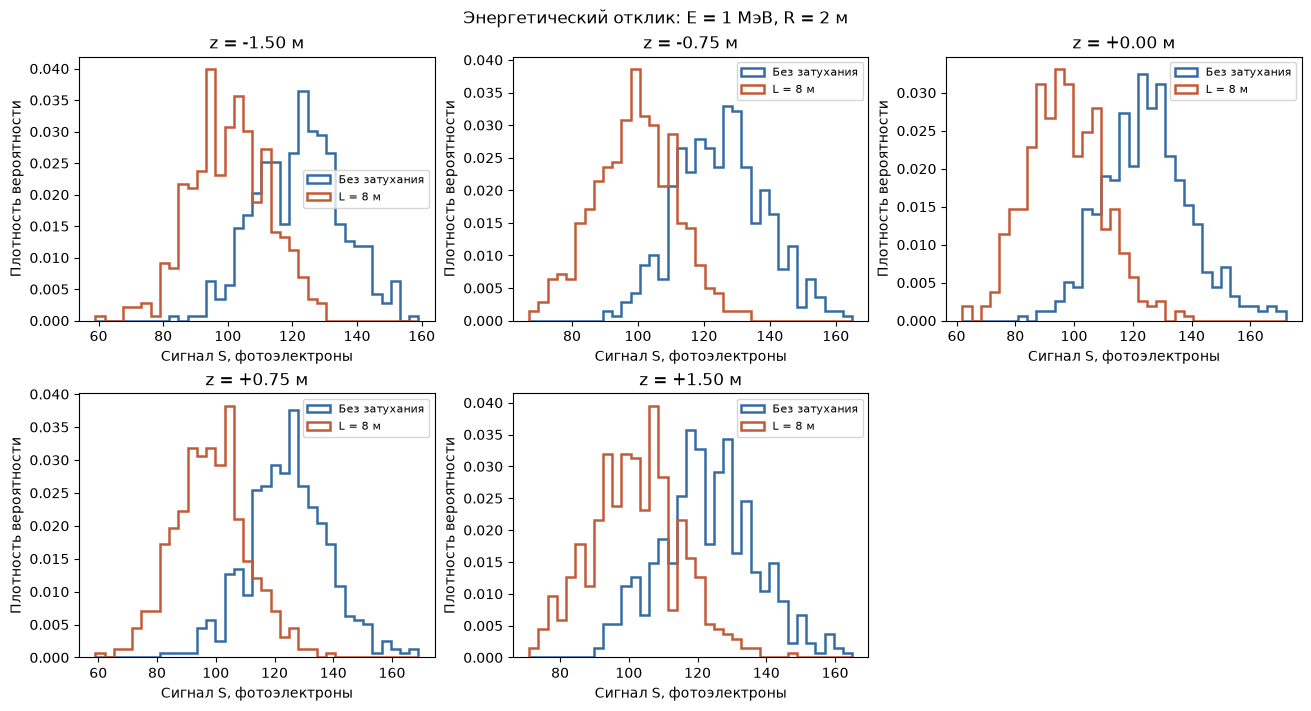

In [4]:
out = Path("results_v4")
out.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for ax, z in zip(axes.flat, z_positions):
    pair = responses[float(z)]
    bins = np.histogram_bin_edges(pair.ravel(), bins=35)
    ax.hist(pair[:, 0], bins=bins, density=True, histtype="step",
            linewidth=1.8, color="#356ca3", label="Без затухания")
    ax.hist(pair[:, 1], bins=bins, density=True, histtype="step",
            linewidth=1.8, color="#c25b38", label="L = 8 м")
    ax.set(title=f"z = {z:+.2f} м", xlabel="Сигнал S, фотоэлектроны",
           ylabel="Плотность вероятности")
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Энергетический отклик: E = 1 МэВ, R = 2 м")
fig.savefig(out / "hw06_response_histograms.png", dpi=160)
plt.show()

**Сравним средние, ширины и относительное разрешение**

 z, м    <S> без     <S> с      std без    std с    отношение
-1.50    122.248    100.738     13.064    11.857    0.8240
-0.75    125.176     99.112     13.376    12.094    0.7918
+0.00    124.854     96.908     14.606    12.697    0.7762
+0.75    124.668     98.438     13.630    12.322    0.7896
+1.50    123.022    101.862     13.968    12.798    0.8280


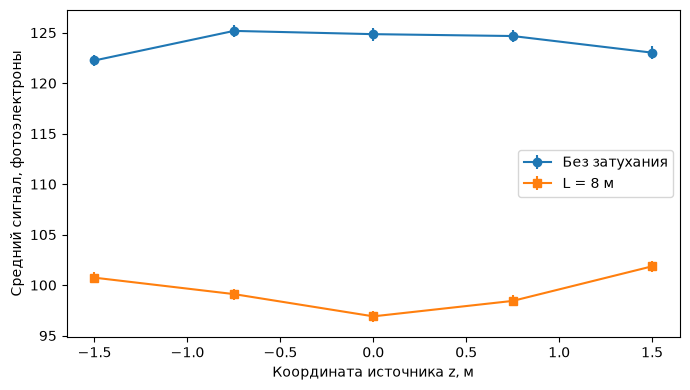

In [5]:
rows = []
print(" z, м    <S> без     <S> с      std без    std с    отношение")
for z in z_positions:
    pair = responses[float(z)]
    means = pair.mean(axis=0)
    stds = pair.std(axis=0, ddof=1)
    sems = stds / np.sqrt(len(pair))
    resolution = stds / means
    rows.append([z, *means, *stds, *sems, *resolution, means[1] / means[0]])
    print(f"{z:+5.2f}  {means[0]:9.3f}  {means[1]:9.3f}  "
          f"{stds[0]:9.3f}  {stds[1]:8.3f}  {means[1]/means[0]:8.4f}")

table = np.array(rows)
np.savetxt(out / "hw06_summary.csv", table, delimiter=",",
           header="z,mean_no,mean_att,std_no,std_att,sem_no,sem_att,rel_no,rel_att,ratio",
           comments="")

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(table[:, 0], table[:, 1], yerr=table[:, 5], fmt="o-", label="Без затухания")
ax.errorbar(table[:, 0], table[:, 2], yerr=table[:, 6], fmt="s-", label="L = 8 м")
ax.set(xlabel="Координата источника z, м", ylabel="Средний сигнал, фотоэлектроны")
ax.legend()
fig.tight_layout()
fig.savefig(out / "hw06_mean_vs_z.png", dpi=160)
plt.show()